# GNN Training and Serving Pipeline Test (4-Node Production Schema)

This notebook demonstrates the end-to-end GNN lifecycle:
1. **Ingest**: Fetching 38-feature snapshots for `router`, `interface`, `vpn`, and `flow` nodes.
2. **Train**: Fitting scalers and training the HetGNN reconstruction model.
3. **Visualize**: Analyzing the training loss and representation diversity.
4. **Evaluate**: Assessing reconstruction MSE on held-out test data to define anomaly thresholds.

In [1]:
import os
import sys
import asyncio
import argparse
import datetime
import pickle
from pathlib import Path
from unittest.mock import patch

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns
import torch

# Ensure gnn/src and gnn/tests are on the path
src_path   = str((Path.cwd().resolve().parent / "src").resolve())
tests_path = str(Path.cwd().resolve())
for _p in [src_path, tests_path]:
    if _p not in sys.path:
        sys.path.insert(0, _p)

import train_hetgnn
import serve
import test_kfp_training_local

from utils.gnn_utils import (
    NODE_TYPES,
    ROUTER_FEATURES, INTERFACE_FEATURES, VPN_FEATURES, FLOW_FEATURES,
    _role_onehot, ROLE_ORDER, ANOMALY_THRESHOLDS, FEATURE_DIMS,
)

pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", palette="muted")
print("Imports OK")


/Users/alvarossl/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/alvarossl/Library/Python/3.9/lib/python/site-packages/google/api_core/_python_version_support.py:237: FutureWarning: You are using a non-supported Python version (3.9.6). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.10, and then update google.api_core.
  warnings.warn(message, FutureWarning)


An error occurred: module 'importlib.metadata' has no attribute 'packages_distributions'
Imports OK


## 1. Configuration & Ingestion

We use today's window (May 27, 2026) from 8am to ensure we have the synchronized topology.

In [2]:
# ── Credentials ─────────────────────────────────────────────────────────────
_local_creds = str((Path.cwd().resolve().parent / "src" / "networkagent.json").resolve())
creds_path = os.getenv("GOOGLE_APPLICATION_CREDENTIALS", _local_creds)
if creds_path and os.path.exists(creds_path):
    os.environ["GOOGLE_APPLICATION_CREDENTIALS"] = creds_path
    print(f"Using credentials: {creds_path}")
else:
    print("Using Application Default Credentials (ADC)")

# ── GCP / Spanner ────────────────────────────────────────────────────────────
os.environ["GOOGLE_CLOUD_PROJECT"] = "gnn-networks"
project_id       = "gnn-networks"
spanner_instance = os.getenv("SPANNER_INSTANCE", "networktopology-instance")
spanner_database = os.getenv("SPANNER_DATABASE", "networktopology-db")
interval_minutes = 0.5  # 30-second cadence

# ── Time windows ─────────────────────────────────────────────────────────────
TRAIN_FROM = datetime.datetime(2026, 5, 27,  8,  0, 0)
TRAIN_TO   = datetime.datetime(2026, 5, 27,  9,  0, 0)
TEST_FROM  = datetime.datetime(2026, 5, 27,  9,  0, 0)
TEST_TO    = datetime.datetime(2026, 5, 27,  9, 15, 0)

output_dir = Path("notebook_artifacts")
output_dir.mkdir(exist_ok=True)

# ── Cache-aware loader ───────────────────────────────────────────────────────
def load_or_fetch(cache_dir, from_time, to_time):
    """Return cached pkl snapshots if present; otherwise fetch from Spanner.
    Falls back to most-recent N snapshots if the window has no data.
    """
    cache_dir = Path(cache_dir)
    pkls = sorted(cache_dir.glob("*.pkl"))
    if pkls:
        print(f"  Cache hit: loading {len(pkls)} snapshots from {cache_dir.name}/")
        return [pickle.load(open(p, "rb")) for p in pkls]
    n = int((to_time - from_time).total_seconds() / (interval_minutes * 60))
    args = argparse.Namespace(
        project=project_id, spanner_instance=spanner_instance,
        spanner_database=spanner_database, interval_minutes=interval_minutes,
        num_snapshots=n, from_time=from_time, to_time=to_time,
    )
    print(f"  Fetching {n} snapshots from Spanner ({from_time} → {to_time}) ...")
    try:
        return test_kfp_training_local.step_ingest(args, cache_dir)
    except RuntimeError:
        print("  No data for window — falling back to most recent snapshots")
        args.from_time = args.to_time = None
        return test_kfp_training_local.step_ingest(args, cache_dir)

print("Loading training snapshots...")
train_snapshots = load_or_fetch(output_dir / "snapshots", TRAIN_FROM, TRAIN_TO)
print(f"  {len(train_snapshots)} training snapshots ready.")

print("Loading test snapshots...")
test_snapshots = load_or_fetch(output_dir / "test_snapshots", TEST_FROM, TEST_TO)
print(f"  {len(test_snapshots)} test snapshots ready.")

Using credentials: /Users/alvarossl/Documents/bt_gnn/gnnsandbox/gnn/src/networkagent.json
Loading training snapshots...
  Cache hit: loading 121 snapshots from snapshots/
  121 training snapshots ready.
Loading test snapshots...
  Cache hit: loading 31 snapshots from test_snapshots/
  31 test snapshots ready.


## 2. Model Training

This runs the GNN pipeline locally. It will:
- Filter any outlier snapshots.
- Fit the `StandardScaler` to the 38 features.
- Train the `HetGNN` autoencoder.

In [3]:
print("Starting training run...")
model, val_loss, gb, history = train_hetgnn.train_hetgnn_on_snapshots(
    snapshot_objects=train_snapshots,
    output_dir=str(output_dir),
    hidden_channels=64,
    num_layers=2,
    epochs_override=50
)
print(f"Training finished. Best Val Loss: {val_loss:.4f}")


Starting training run...
2026-05-27 16:36:46,544 - train_hetgnn - WARNING - Dropped bad snapshot 2026-05-27T08:01:00 (feature '('router', 'cpu')' mean=0.5989, z=4.1σ)
2026-05-27 16:36:46,545 - train_hetgnn - WARNING - Dropped bad snapshot 2026-05-27T08:37:00 (feature '('router', 'cpu')' mean=0.6994, z=4.9σ)
2026-05-27 16:36:46,545 - train_hetgnn - INFO - Filtered 2 bad snapshot(s) — 119 remaining
2026-05-27 16:36:46,545 - train_hetgnn - INFO - Dataset split: 95 training, 24 validation snapshots
2026-05-27 16:36:46,546 - train_hetgnn - INFO - Fitting scalers on training snapshots only...
2026-05-27 16:36:46,572 - utils.gnn_utils - INFO - Fitted scaler for 'router' on 1710 node observations
2026-05-27 16:36:46,578 - utils.gnn_utils - INFO - Fitted scaler for 'interface' on 8740 node observations
2026-05-27 16:36:46,578 - utils.gnn_utils - INFO - Fitted scaler for 'vpn' on 285 node observations
2026-05-27 16:36:46,580 - utils.gnn_utils - INFO - Fitted scaler for 'flow' on 380 node observa

## 3. Loss Visualization

Plotting the convergence of the reconstruction error.

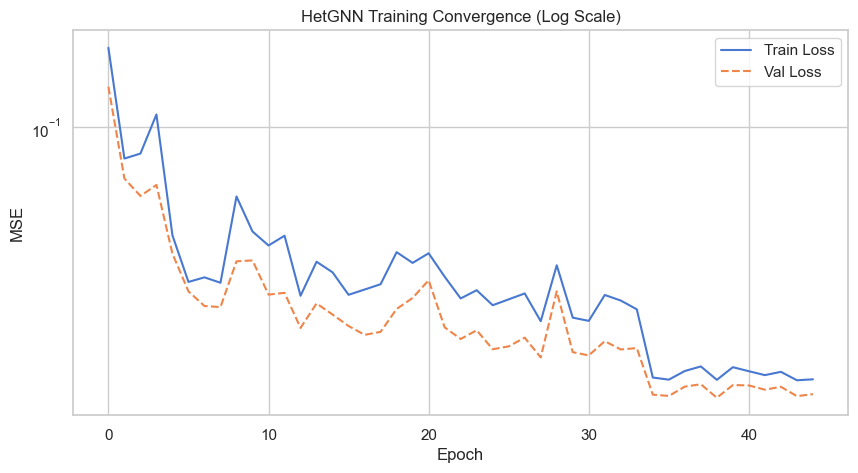

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(history['train'], label='Train Loss')
plt.plot(history['val'], label='Val Loss', linestyle='--')
plt.yscale('log')
plt.title("HetGNN Training Convergence (Log Scale)")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

## 4. Anomaly Detection Assessment

We run inference on the **held-out test set** and analyze the reconstruction error distribution.

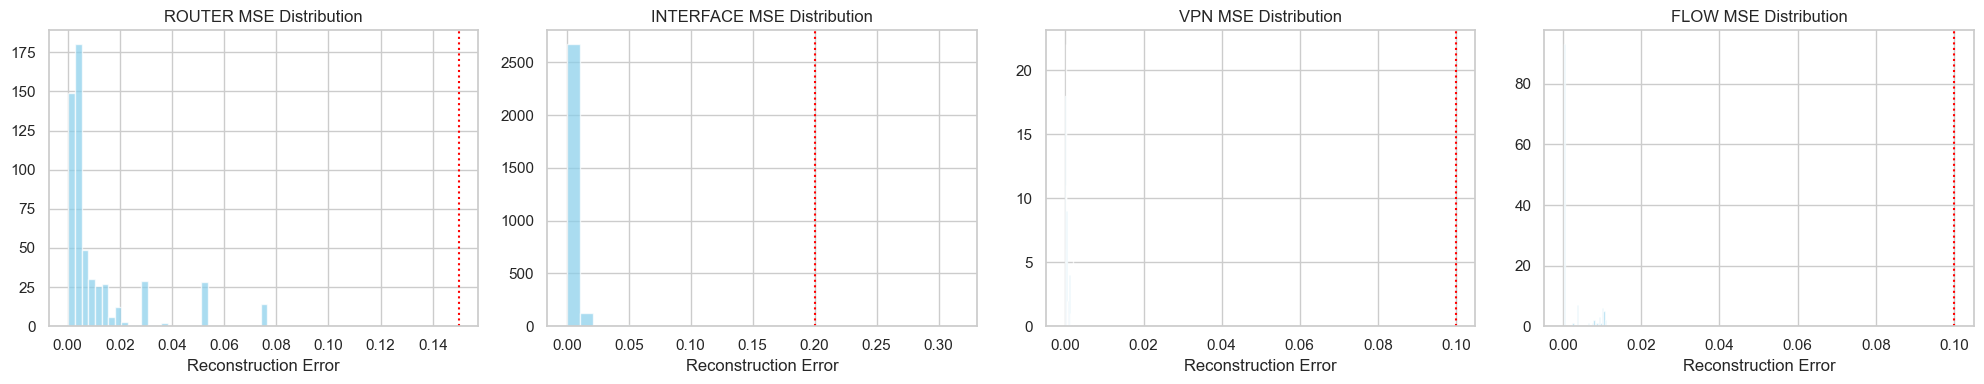

In [5]:
model.eval()
criterion = torch.nn.MSELoss(reduction='none')
test_hetero = [gb.process_snapshot(s) for s in test_snapshots]

node_type_errors = {nt: [] for nt in NODE_TYPES}

with torch.no_grad():
    for hdata in test_hetero:
        recons, embs = model(hdata.x_dict, hdata.edge_index_dict)
        for ntype, recon in recons.items():
            if ntype in hdata.x_dict:
                mse = criterion(recon, hdata.x_dict[ntype]).mean(dim=1)
                node_type_errors[ntype].extend(mse.cpu().numpy())

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for i, ntype in enumerate(['router', 'interface', 'vpn', 'flow']):
    errors = node_type_errors[ntype]
    if errors:
        axes[i].hist(errors, bins=30, color='skyblue', alpha=0.7)
        axes[i].axvline(ANOMALY_THRESHOLDS.get(ntype, 0.5), color='red', linestyle=':', label='Threshold')
        axes[i].set_title(f"{ntype.upper()} MSE Distribution")
        axes[i].set_xlabel("Reconstruction Error")
    else:
        axes[i].set_title(f"{ntype.upper()} (No Data)")
plt.tight_layout()
plt.show()

## 4b. Test-set Evaluation Summary

Compute a per-type MSE summary table on the held-out test set and compare against anomaly thresholds to understand model sensitivity.

In [6]:
import statistics

print('── Test-set MSE per node type ───────────────────────────────────────')
print(f"  {'Node type':<16} {'n':>6}  {'mean MSE':>10}  {'max MSE':>10}  {'threshold':>10}  {'anomalies':>10}")
print('  ' + '-'*68)
for ntype in NODE_TYPES:
    scores = node_type_errors.get(ntype, [])
    if not scores:
        continue
    thresh = ANOMALY_THRESHOLDS.get(ntype, 0.50)
    n_anom = sum(1 for s in scores if s > thresh)
    print(f"  {ntype:<16} {len(scores):>6}  {statistics.mean(scores):>10.4f}  "
          f"{max(scores):>10.4f}  {thresh:>10.2f}  {n_anom:>9} ({100*n_anom/len(scores):.1f}%)")


── Test-set MSE per node type ───────────────────────────────────────
  Node type             n    mean MSE     max MSE   threshold   anomalies
  --------------------------------------------------------------------
  router              558      0.0111      0.0766        0.15          0 (0.0%)
  interface          2852      0.0046      0.3151        0.20          9 (0.3%)
  vpn                  93      0.0004      0.0019        0.10          0 (0.0%)
  flow                124      0.0023      0.0111        0.10          0 (0.0%)


## 5. Serve (Inference)

Test the production serving code.
In production, `serve.py` queries Google Cloud Storage to find the latest trained model (via `latest_run.json`). To test it locally we temporarily patch those loader functions to point to the artifacts we just trained in our `notebook_artifacts` directory.

This execution will:
1. Reload the model and scalers we just saved.
2. Fetch one *new* real snapshot from Spanner.
3. Perform a forward pass to compute node embeddings and MSE reconstruction error.
4. **Write the results** directly back to the Spanner `NodeEmbedding` table.
5. Print the anomaly scores and an RCA decision tree.

In [7]:
print('Setting up serving components with local artifacts instead of GCS...')

def mock_load_manifest():
    return {'run_id': 'notebook_test_run'}

def mock_download_artefacts(manifest):
    return output_dir

async def test_serving():
    with patch('serve._load_manifest', side_effect=mock_load_manifest), \
         patch('serve._download_artefacts', side_effect=mock_download_artefacts), \
         patch('serve.SPANNER_INSTANCE', spanner_instance), \
         patch('serve.SPANNER_DATABASE', spanner_database), \
         patch('serve.GOOGLE_CLOUD_PROJECT', project_id):

        results = await serve._run_inference()

        print('\n─── INFERENCE RESULTS ─────────────────────────────────────────')
        print(f"Snapshot timestamp : {results['snapshot_timestamp']}")
        print(f"Total anomalies    : {results['anomaly_count']}")

        thresholds = serve._cache.get('thresholds', serve._FALLBACK_THRESHOLDS)
        print('\n  Node Type        Nodes   Anomalies   Threshold')
        print('  ' + '-'*52)
        for ntype, scores in results['anomaly_scores'].items():
            thresh = thresholds.get(ntype, 0.50)
            n_anom = sum(1 for s in scores if s > thresh)
            print(f"  {ntype:<18} {len(scores):>5}   {n_anom:>9}   MSE>{thresh:.2f}")

        # ── RCA Decision Tree ────────────────────────────────────────────────
        print('\n── RCA Decision Tree ───────────────────────────────────────────')
        r_scores   = results['anomaly_scores'].get('router', [])
        r_expls    = results.get('anomaly_explanations', {}).get('router', [])
        vpn_scores = results['anomaly_scores'].get('vpn', [])
        ifc_scores = results['anomaly_scores'].get('interface', [])
        r_thresh   = thresholds.get('router', 0.15)
        v_thresh   = thresholds.get('vpn', 0.50)
        i_thresh   = thresholds.get('interface', 0.50)

        anom_routers = [(i, s) for i, s in enumerate(r_scores) if s > r_thresh]
        if not anom_routers:
            print('  No anomalous routers detected — network looks healthy.')
        else:
            for idx, score in anom_routers[:5]:
                expl     = r_expls[idx] if idx < len(r_expls) else {}
                top_f    = expl.get('top_features', [])
                feat_str = ', '.join(f['feature'] for f in top_f) if top_f else 'n/a'
                print(f"  ▶ Router[{idx}] MSE={score:.4f}  top features: {feat_str}")
                anom_vpn = [i for i, s in enumerate(vpn_scores) if s > v_thresh]
                anom_ifc = [i for i, s in enumerate(ifc_scores) if s > i_thresh]
                if anom_vpn:
                    print(f"    ↳ {len(anom_vpn)} VPN(s) also anomalous — possible VPN tunnel failure")
                elif anom_ifc:
                    print(f"    ↳ {len(anom_ifc)} interface(s) also anomalous — likely interface degradation")
                else:
                    print(f"    ↳ VPN and interfaces healthy — possible CPU/memory issue")

await test_serving()


Setting up serving components with local artifacts instead of GCS...
2026-05-27 16:37:12,898 - gnn.serve - INFO - Loading model for run_id=notebook_test_run...
2026-05-27 16:37:12,900 - utils.data - INFO - Initializing SpannerDataset: instance_id=networktopology-instance, database_id=networktopology-db, num_snapshots=1, interval_minutes=5.0, project_id=gnn-networks, from_time=None, to_time=None
2026-05-27 16:37:12,957 - utils.data - INFO - SpannerDataset initialized successfully


Created multiplexed session.


2026-05-27 16:37:13,460 - projects/gnn-networks/instances/networktopology-instance/databases/networktopology-db - INFO - Created multiplexed session.
2026-05-27 16:37:15,735 - utils.data - INFO - Generated 1 timestamps from 2026-05-27T15:35:05 to 2026-05-27T15:35:05
2026-05-27 16:37:15,736 - utils.data - INFO - Fetching snapshot for timestamp: 2026-05-27T15:35:05
2026-05-27 16:37:16,084 - utils.data - INFO - Fetched 18 routers
2026-05-27 16:37:16,131 - utils.data - INFO - Fetched 92 interfaces
2026-05-27 16:37:16,291 - utils.data - INFO - peer_of pairs: 153
2026-05-27 16:37:16,309 - utils.data - INFO - BGP sessions processed for VPN peer counts: 8 VRF→VPN mappings
2026-05-27 16:37:16,400 - utils.data - INFO - Fetched 3 VPN nodes
2026-05-27 16:37:16,418 - utils.data - INFO - member_of pairs: 8
2026-05-27 16:37:16,485 - utils.data - INFO - Device→router: 8 device(s) resolved via gateway IP fallback
2026-05-27 16:37:16,584 - utils.data - INFO - runs_over edges: 4
2026-05-27 16:37:16,585 -

Created multiplexed session.
Created multiplexed session.


2026-05-27 16:37:17,606 - projects/gnn-networks/instances/networktopology-instance/databases/networktopology-db - INFO - Created multiplexed session.
2026-05-27 16:37:17,691 - utils.data - INFO - Generated 2 timestamps from 2026-05-27T15:30:05 to 2026-05-27T15:35:05
2026-05-27 16:37:17,692 - utils.data - INFO - Fetching snapshot for timestamp: 2026-05-27T15:30:05
2026-05-27 16:37:18,206 - utils.data - INFO - Fetched 18 routers
2026-05-27 16:37:18,276 - utils.data - INFO - Fetched 92 interfaces
2026-05-27 16:37:18,522 - utils.data - INFO - peer_of pairs: 153
2026-05-27 16:37:18,548 - utils.data - INFO - BGP sessions processed for VPN peer counts: 8 VRF→VPN mappings
2026-05-27 16:37:18,752 - utils.data - INFO - Fetched 3 VPN nodes
2026-05-27 16:37:18,794 - utils.data - INFO - member_of pairs: 8
2026-05-27 16:37:18,867 - utils.data - INFO - Device→router: 8 device(s) resolved via gateway IP fallback
2026-05-27 16:37:19,083 - utils.data - INFO - runs_over edges: 4
2026-05-27 16:37:19,084 -

## 6. Synthetic Anomaly Inference and Diagnosis

Load synthetic snapshots with injected anomalies (e.g. a CRC error spike or CPU spike), run inference, and visualize how the GNN flags specific nodes.

Run `python3 generate_anomalies.py` first to create the synthetic data directory.

In [8]:
import joblib
from utils.gnn_utils import GraphBuilder, FEATURE_DIMS
from model.hetgnn import HetGNN

_ckpt = torch.load(output_dir / 'model.pth', map_location='cpu', weights_only=False)

_scalers  = joblib.load(output_dir / 'scalers.pkl')
gb_synth  = GraphBuilder(scalers=_scalers)

_sample    = gb_synth.process_snapshot(
    pickle.load(open(sorted((output_dir / 'snapshots').glob('*.pkl'))[0], 'rb'))
)
_node_types = list(_sample.x_dict.keys())
_edge_types = list(_sample.edge_index_dict.keys())

model_synth = HetGNN(
    (_node_types, _edge_types),
    hidden_channels=_ckpt.get('hidden_channels', 64),
    out_channels=64,
    num_layers=_ckpt.get('num_layers', 2),
)
model_synth.set_input_dims(FEATURE_DIMS)
model_synth.load_state_dict(_ckpt['model_state_dict'])
model_synth.eval()
print(f"Loaded model from {output_dir / 'model.pth'}  "
      f"(val_loss={_ckpt.get('val_loss', float('nan')):.4f})")


Loaded model from notebook_artifacts/model.pth  (val_loss=0.0181)


Loading synthetic snapshots from /Users/alvarossl/Documents/bt_gnn/gnnsandbox/gnn/tests/anomaly_synthetic_data...
Running inference on snapshot: 2026-05-19T12:00:30

─── SYNTHETIC INFERENCE RESULTS ────────────────────────────────
[!] ANOMALY: router     ID: router:ce1-hub                 MSE: 3.4285 (>0.15) Top: cpu
[!] ANOMALY: interface  ID: router:ce1-hub:interface:eth0  MSE: 4.1821 (>0.20) Top: carrier_changes


/var/folders/2t/j0dr3dp90kg6cfbm6pqsptjr0169m4/T/ipykernel_67820/1532918115.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


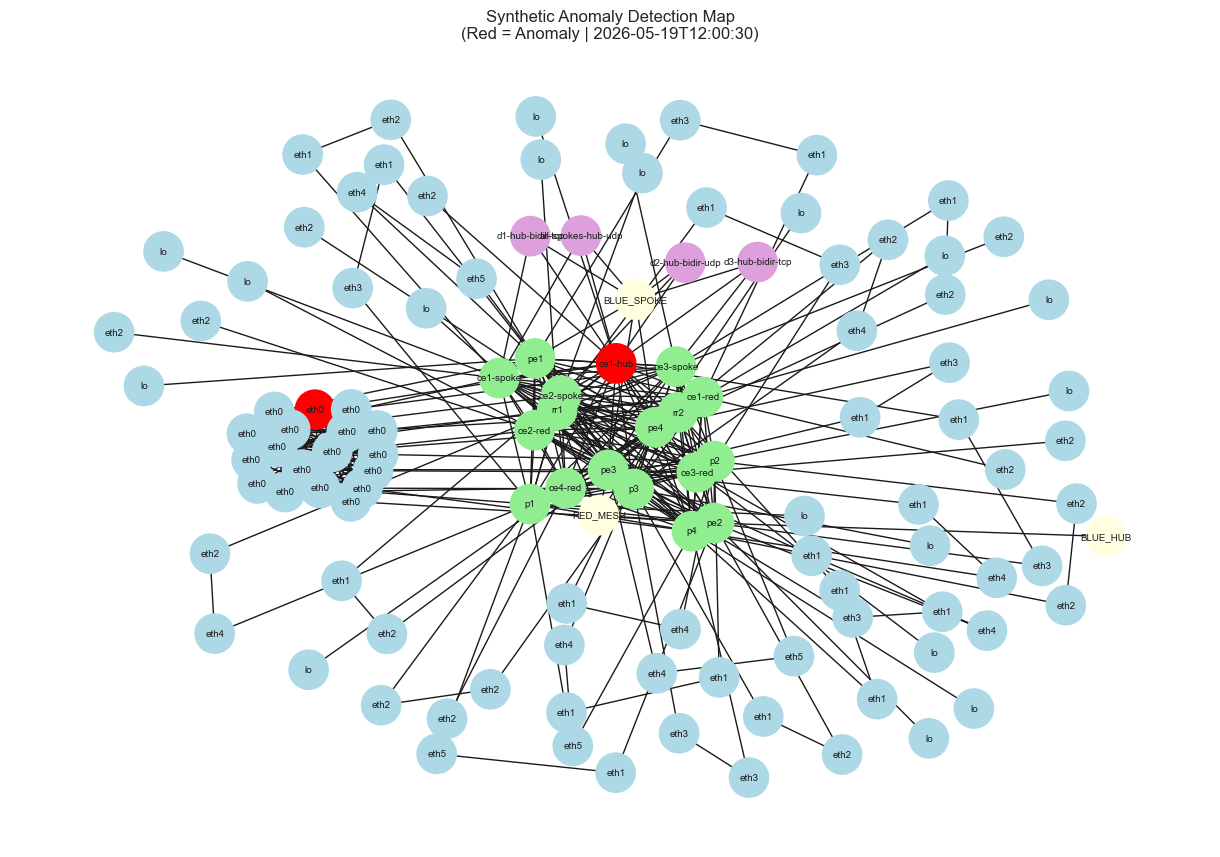

In [9]:
import json
import networkx as nx

synthetic_dir = Path('/Users/alvarossl/Documents/bt_gnn/gnnsandbox/gnn/tests/anomaly_synthetic_data')

_feat_names  = {
    'router':    ROUTER_FEATURES,
    'interface': INTERFACE_FEATURES,
    'vpn':       VPN_FEATURES,
    'flow':      FLOW_FEATURES,
}
_type_colors = {
    'router':    'lightgreen',
    'interface': 'lightblue',
    'vpn':       'lightyellow',
    'flow':      'plum',
}

def load_synthetic_snapshots(data_dir):
    snaps = []
    for p in sorted(Path(data_dir).glob('*.json')):
        with open(p) as f:
            snaps.append(json.load(f))
    return snaps

def test_synthetic_inference():
    print(f'Loading synthetic snapshots from {synthetic_dir}...')
    synthetic_snapshots = load_synthetic_snapshots(synthetic_dir)
    if not synthetic_snapshots:
        print("No synthetic snapshots found. Run 'python3 generate_anomalies.py' first.")
        return

    latest_snap = synthetic_snapshots[-1]
    print(f"Running inference on snapshot: {latest_snap['timestamp']}")

    hetero_data = gb_synth.process_snapshot(latest_snap)
    node_id_map = hetero_data.node_id_map

    model_synth.eval()
    with torch.no_grad():
        recon_dict, _ = model_synth(hetero_data.x_dict, hetero_data.edge_index_dict)

    print('\n─── SYNTHETIC INFERENCE RESULTS ────────────────────────────────')
    found_anomalies = []

    for ntype, recon in recon_dict.items():
        if ntype not in hetero_data.x_dict:
            continue
        orig      = hetero_data[ntype].x
        feat_mse  = (recon - orig) ** 2
        node_mse  = feat_mse.mean(dim=1)
        threshold  = ANOMALY_THRESHOLDS.get(ntype, 0.50)
        feat_names = _feat_names.get(ntype, [])

        for idx in range(node_mse.size(0)):
            score = node_mse[idx].item()
            if score > threshold:
                node_id       = node_id_map[ntype][idx]
                top_feat_idx  = torch.argmax(feat_mse[idx]).item()
                top_feat_name = feat_names[top_feat_idx] if top_feat_idx < len(feat_names) else 'unknown'
                found_anomalies.append({'id': node_id, 'type': ntype,
                                        'score': score, 'top_feature': top_feat_name})
                print(f"[!] ANOMALY: {ntype:<10} ID: {node_id:<30} "
                      f"MSE: {score:.4f} (>{threshold:.2f}) Top: {top_feat_name}")

    if not found_anomalies:
        print('  No anomalies detected above threshold.')

    # ── Graph visualization ──────────────────────────────────────────────────
    G = nx.Graph()
    node_color_list = []
    labels   = {}
    anom_ids = {a['id'] for a in found_anomalies}

    for node in latest_snap['nodes']:
        if node['type'] not in _type_colors:
            continue
        G.add_node(node['id'])
        labels[node['id']] = node.get('hostname', node.get('name', node.get('id', '')))
        node_color_list.append('red' if node['id'] in anom_ids else _type_colors[node['type']])

    for edge in latest_snap['edges']:
        if edge['source'] in G and edge['target'] in G:
            G.add_edge(edge['source'], edge['target'])

    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(G, k=0.3, seed=42)
    nx.draw(G, pos, labels=labels, with_labels=True,
            node_color=node_color_list, node_size=800, font_size=7)
    plt.title(f"Synthetic Anomaly Detection Map\n"
              f"(Red = Anomaly | {latest_snap['timestamp']})")
    plt.tight_layout()
    plt.show()

test_synthetic_inference()
